<a href="https://colab.research.google.com/github/dkalchenko01/UA-Locations-NER-Deep-Learning/blob/quality/notebooks/06_loc_quality.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Location label quality

We check the quality of location annotations in our training data using an LLM.

First, we inspect `labeling_sample.csv` to understand its annotation style. We use it as a reference because its texts resemble the test set.

Then we ask the LLM to flag potentially incorrect training labels and explain why. We start with a small sample and review its answers before checking more texts.

If only a small share of texts has bad labels, we may exclude them from training instead of relabeling. If we find a common problem, we will consider fixing it.

Original data stays unchanged. We save all suggestions separately. Validation and holdout labels are not changed at this stage.

# Environment Setup

In [8]:
import os
import ast
import json
import time
import sys
import base64
import subprocess
from datetime import datetime, timezone
from pathlib import Path

import pandas as pd
import requests
from tqdm.auto import tqdm
from google.colab import drive, userdata

In [9]:
if "google.colab" in sys.modules:
    from google.colab import userdata
    token = userdata.get("GITHUB_TOKEN")
    root = "/content"
else:
    from kaggle_secrets import UserSecretsClient
    token = UserSecretsClient().get_secret("GITHUB_TOKEN")
    root = "/kaggle/working"

repo = "UA-Locations-NER-Deep-Learning"
branch = "main"
repo_dir = f"{root}/{repo}"

auth = base64.b64encode(f"x-access-token:{token}".encode()).decode()
env = os.environ.copy()
env["GIT_CONFIG_COUNT"] = "1"
env["GIT_CONFIG_KEY_0"] = "http.extraheader"
env["GIT_CONFIG_VALUE_0"] = f"AUTHORIZATION: basic {auth}"

if not os.path.exists(repo_dir):
    subprocess.run(
        ["git", "clone", "-b", branch, f"https://github.com/dkalchenko01/{repo}.git", repo_dir],
        env=env, check=True
    )

print("Repository:", repo_dir)

Repository: /content/UA-Locations-NER-Deep-Learning


In [10]:
sys.path.insert(0, repo_dir)
from src.data_io import get_data_dir

ENVIRONMENT = "colab" if root == "/content" else "kaggle"

data_dir = Path(get_data_dir(ENVIRONMENT))
print("Data directory:", data_dir)

100%|██████████| 811M/811M [00:40<00:00, 21.0MB/s]

Extracting files...


Data directory: /root/.cache/kagglehub/competitions/kse-ua-location-extraction-2026


# `labeling_sample.csv` detailed analysis

In [11]:
sample_df = pd.read_csv(data_dir / "labeling_sample.csv")
test_df = pd.read_csv(data_dir / "test.csv")

We inspect the sample texts and their annotated locations to understand how are they labeled.

In [12]:
sample_df["spans"] = sample_df["loc_markers"].apply(ast.literal_eval)
sample_df["annotated_locations"] = [[text[start:end] for start, end in spans] for text, spans in zip(sample_df["text"], sample_df["spans"])]

print("Texts:", len(sample_df))

Texts: 26


In [13]:
for sample_index, row in sample_df.iterrows():
  print(f"\nSample: {sample_index}")
  print(row["text"])
  print("\nAnnotated locations:", row["annotated_locations"])
  print("-" * 80)


Sample: 0
-261.310

Annotated locations: []
--------------------------------------------------------------------------------

Sample: 1
Проспект Бандери стоїть, як і пів міста… довго ще??

Життя🫶Оболонь

Annotated locations: ['Проспект Бандери']
--------------------------------------------------------------------------------

Sample: 2
☢️Радіаційний фон (мкР/год) по Київщині станом на 9 год 28 серпня:

Чорнобиль - 19
Київ - 12
Тетерів - 9
Фастів - 11
Біла Церква - 13
Миронівка - 13
Бориспіль - 13
Яготин - 12
Баришівка – 10

Всі показники у межах норми ✅

ℹ️ Нагадуємо, що допустиме значення рівня радіаційного фону до 25 мкР/год

Сайт💧Instagram💧Facebook💧YouTube

Annotated locations: ['Київщині', 'Чорнобиль', 'Київ', 'Тетерів', 'Фастів', 'Біла Церква', 'Миронівка', 'Бориспіль', 'Яготин', 'Баришівка']
--------------------------------------------------------------------------------

Sample: 3
Друзі. Останні дві ночі, і ще декілька наступних, ми з вами будемо відчувати певний дискомфорт у з

**Manual inspection findings:**

- Location names in channel signatures are not labeled.
- Geographic names inside organization names and job titles are often left out.
- Labels include cities, districts, streets, stations and addresses. Some include the location type and building number.
- Some annotations look incomplete: sample 25 cuts building number `17` to `1`.
- Some direct location mentions are missing, especially in samples 5 and 18. We cannot yet explain these omissions with a consistent rule.

Many sample posts concern Kyiv. No texts overlap with test, even after ignoring capitalization and extra whitespace.

## Sample vs. test

We compare text lengths and common post features.

In [14]:
patterns = {
    "line breaks (%)": r"\n",
    "emoji pattern (%)": r"[\U0001F300-\U0001FAFF]",
    "URLs (%)": r"https?://|www\.",
    "hashtags (%)": r"(?<!\w)#\w+",
    "mentions (%)": r"(?<!\w)@\w+",
    "digits (%)": r"\d",
    "UK letters (%)": r"[іїєґІЇЄҐ]",
    "ru letters (%)": r"[ыэъёЫЭЪЁ]"
}

comparison = {}
for name, df in {"sample": sample_df, "test": test_df}.items():
  texts = df["text"].dropna()
  lengths = texts.str.len()
  values = {
      "texts": len(texts),
      "median chars": lengths.median(),
      "p95 chars": lengths.quantile(0.95),
      "max chars": lengths.max()
  }
  for feature, pattern in patterns.items():
    values[feature] = texts.str.contains(pattern).mean() * 100
  comparison[name] = values

pd.DataFrame(comparison).round(1)

,sample,test
texts,26.0,477.0
median chars,217.5,264.0
p95 chars,814.0,1123.2
max chars,1118.0,3682.0
line breaks (%),80.8,85.1
emoji pattern (%),61.5,51.8
URLs (%),0.0,4.0
hashtags (%),3.8,3.6
mentions (%),7.7,3.8
digits (%),57.7,58.5


Much better than train vs. test.

Kyiv mentions and urban locations:
how often test texts mention Kyiv, streets, districts and transport locations

In [16]:
topic_patterns = {
    "Kyiv": r"\b(?:київ|києв|киев|київськ|киевск)[а-яіїєґё]*\b",

    "Kyiv region": (
        r"\bкиївщин[а-яіїєґ]*\b|\bкиевщин[а-яё]*\b|"
        r"\bкиївськ[а-яіїєґ]*\s+област[а-яіїєґ]*\b|"
        r"\bкиевск[а-яё]*\s+област[а-яё]*\b"
    ),

    "metro / stations / bridges": (
        r"\b(?:метро|станці[а-яіїєґ]*|станци[а-яё]*|"
        r"вокзал[а-яіїєґё]*|міст|мост|моста|мосту|"
        r"мостом|мосте|мости|мосты|мостів|мостов)\b"
    ),
}

topic_rows = []

for feature, pattern in topic_patterns.items():
  result = {"pattern": feature}

  for name, df in {"sample": sample_df, "test": test_df}.items():
      matched = df["text"].str.contains(pattern, case=False, regex=True, na=False)
      result[f"{name} texts"] = matched.sum()
      result[f"{name} (%)"] = matched.mean() * 100
  topic_rows.append(result)

pd.DataFrame(topic_rows).set_index("pattern").round(1)

,sample texts,sample (%),test texts,test (%)
pattern,,,,
Kyiv,12,46.2,195,40.9
Kyiv region,2,7.7,30,6.3
metro / stations / bridges,4,15.4,11,2.3


Inspecting examples

In [17]:
import re

for feature, pattern in topic_patterns.items():
  matched = test_df["text"].str.contains(pattern, case=False, regex=True, na=False)
  candidates = test_df.loc[matched]
  examples = candidates.sample(n=min(2, len(candidates)), random_state=17)
  print(f"\n{feature}")
  for row in examples.itertuples(index=False):
    matches = [m.group() for m in re.finditer(pattern, row.text, flags=re.IGNORECASE)]
    print("Text ID:", row.text_id)
    print("Matched:", matches)
    print(row.text)
    print("-" * 80)


Kyiv
Text ID: 0
Matched: ['Київ']
❗️Кількість поранених зросла до трьох, – Кличко

Київ — пряма трансляція 👈
--------------------------------------------------------------------------------
Text ID: 320
Matched: ['Києві']
‼️ У Києві знищили ще одну історичну будівлю‼️

 Її побудували ще у 19 столітті. А натомість столичні бізнесмени планують звести ... новий ЖК.
--------------------------------------------------------------------------------

Kyiv region
Text ID: 39
Matched: ['Київщині']
На Київщині та околицях столиці буде чутно вибухи

У Білоцерківському районі сьогодні впродовж дня проводитимуть знищення вибухонебезпечних предметів.

Так, може бути гучно, але вибухи планові, тому не хвилюйтесь.
ㅤ
  Хуйовий Київ | Надіслати новину
--------------------------------------------------------------------------------
Text ID: 290
Matched: ['Київщини']
💥 Троє людей поранені від атаки росіян в одному з районів Київщини

Від падіння уламків ракет та «шахедів» опіки отримала 69-річна жінка, у 

Sample and test share Kyiv-related topics, urban locations and channel signatures. These contexts should be included in our label audit.

Keyword counts are only approximate: matches may refer to channel names, organizations or generic words rather than actual locations.

## Adversarial check: sample vs. test

In [18]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedGroupKFold, cross_val_score
from sklearn.pipeline import make_pipeline

texts = pd.concat([sample_df["text"], test_df["text"]], ignore_index=True)
labels = [0] * len(sample_df) + [1] * len(test_df)
groups = texts.str.lower().str.split().str.join(" ")

classifier = make_pipeline(
    TfidfVectorizer(analyzer="char", ngram_range=(2, 4), min_df=2, max_features=20000),
    LogisticRegression(class_weight="balanced", max_iter=1000, random_state=17)
)
cv = StratifiedGroupKFold(n_splits=3, shuffle=True, random_state=17)
auc = cross_val_score(classifier, texts, labels, groups=groups, cv=cv, scoring="roc_auc")

print("ROC AUC per fold:", auc.round(3))
print("Mean ROC AUC:", round(auc.mean(), 3))

ROC AUC per fold: [0.63  0.66  0.516]
Mean ROC AUC: 0.602


The classifier only weakly separates sample from test

# LLM as a judge

labeling_sample like annotations on 1000 random train rows

In [19]:
%pip install -q openai

Azure configuration

In [20]:
import asyncio
from urllib.parse import urlsplit
from google.colab import userdata
from openai import AsyncOpenAI

API_KEY = userdata.get("AZURE_OPENAI_API_KEY")
ENDPOINT = userdata.get("AZURE_OPENAI_ENDPOINT")
DEPLOYMENT = userdata.get("AZURE_OPENAI_DEPLOYMENT")

url = urlsplit(ENDPOINT)
BASE_URL = f"{url.scheme}://{url.netloc}/openai/v1/"

# Initialize the asynchronous client
client = AsyncOpenAI(
    api_key=API_KEY,
    base_url=BASE_URL,
    max_retries=5,
    timeout=120.0,
)
print("Deployment:", DEPLOYMENT)
print("Base URL:", BASE_URL)

Deployment: gpt-4.1-mini
Base URL: https://ner-llm-audit-2026.cognitiveservices.azure.com/openai/v1/


Test connection

In [21]:
response = await client.chat.completions.create(
    model=DEPLOYMENT,
    messages=[{"role": "user", "content": "Reply with OK."}],
    temperature=0,
    max_tokens=20)

print(response.choices[0].message.content)

OK.


Output directory

In [26]:
from pathlib import Path
from google.colab import drive

if not os.path.ismount("/content/drive"):
  drive.mount("/content/gdrive")
  DRIVE_ROOT = Path("/content/gdrive/MyDrive")
else:
  DRIVE_ROOT = Path("/content/drive/MyDrive")

OUTPUT_DIR = (DRIVE_ROOT / "ner_results" / "llm annotations" / "labeling_sample")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
print("Output directory:", OUTPUT_DIR)

Mounted at /content/gdrive
Output directory: /content/gdrive/MyDrive/ner_results/llm annotations/labeling_sample


Processing configuration

In [23]:
# Experiment settings
SEED = 17
SAMPLE_SIZE = 1000

# LLM settings
TEMPERATURE = 0
BATCH_SIZE = 20
MAX_CONCURRENT_REQUESTS = 5
MAX_OUTPUT_TOKENS = 3000

# Azure deployment rate limits
TPM_LIMIT = 100_000
RPM_LIMIT = 100

Fixed 1000 train sample for all experiments:

In [24]:
uk_df = pd.read_csv(data_dir / "uk_geo_dataset.csv")
uk_df["row_id"] = uk_df.index

manifest = pd.read_parquet(Path(repo_dir) / "data/splits/validation_manifest_v2.parquet")

train_ids = manifest.loc[(manifest["source"] == "uk") & (manifest["split"] == "train"),"row_id"]
train_df = uk_df.loc[uk_df["row_id"].isin(train_ids)].copy()
print("Ukrainian train size:", len(train_df))

Ukrainian train size: 805983


In [27]:
train_df["text_length"] = train_df["text"].str.len()
train_df["n_locations"] = train_df["loc_markers"].fillna("[]").apply(lambda x: len(ast.literal_eval(x)))
train_df["loc_group"] = train_df["n_locations"].clip(upper=3)

train_df["length_group"] = pd.qcut(train_df["text_length"], q=4,labels=False, duplicates="drop")
display(
    pd.crosstab(train_df["loc_group"], train_df["length_group"], normalize="all").round(4)
)

length_group,0,1,2,3
loc_group,,,,
0,0.2239,0.1966,0.1865,0.1618
1,0.0269,0.0367,0.0449,0.0510
2,0.0046,0.0092,0.0143,0.0206
3,0.0008,0.0027,0.0061,0.0136


Stratified sampling

In [28]:
from sklearn.model_selection import train_test_split

strata = train_df["loc_group"].astype(str) + "_" + train_df["length_group"].astype(str)

_, experiment_df = train_test_split(
    train_df,
    test_size=SAMPLE_SIZE,
    stratify=strata,
    random_state=SEED,
)
experiment_df = experiment_df.sort_values("row_id").reset_index(drop=True)
print("Experiment sample size:", len(experiment_df))
display(experiment_df.head())

Experiment sample size: 1000


,text,loc_markers,org_markers,per_markers,is_valid,row_id,text_length,n_locations,loc_group,length_group
0,"Бразилець вже понад два роки грає за ПСЖ, а ві...",[],"[(37, 40)]",[],0,1910,73,0,0,1
1,Твоя історія ще не закінчена…Згідно зі світово...,[],[],[],0,2987,107,0,0,2
2,"За версією слідства, посадовець вимагав гроші ...",[],[],[],0,3761,137,0,0,3
3,Народний депутат і за сумісництвом мер Львова ...,"[(39, 45)]",[],"[(46, 53)]",0,4087,89,1,1,1
4,Олександр Біленький та Валерій Головко у своїх...,[],[],"[(0, 19), (23, 38)]",0,4236,102,0,0,2


Compare train and sample distributions

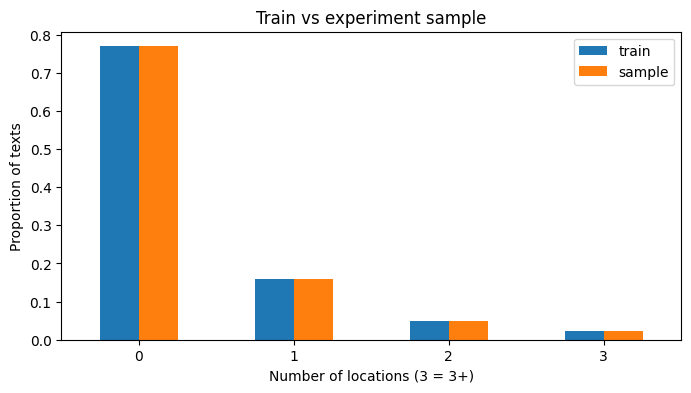

In [30]:
import matplotlib.pyplot as plt
loc_distribution = pd.DataFrame({
    "train": train_df["loc_group"].value_counts(normalize=True),
    "sample": experiment_df["loc_group"].value_counts(normalize=True)}).sort_index()

length_distribution = pd.DataFrame({
    "train": train_df["text_length"].describe(),
    "sample": experiment_df["text_length"].describe()})
loc_distribution.plot.bar(figsize=(8, 4))
plt.xlabel("Number of locations (3 = 3+)")
plt.ylabel("Proportion of texts")
plt.title("Train vs experiment sample")
plt.xticks(rotation=0)
plt.show()

Save shared experiment sample

In [31]:
SAMPLE_PATH = OUTPUT_DIR.parent / "experiment_sample_1000.csv"
experiment_df[["row_id", "text", "loc_markers"]].to_csv(SAMPLE_PATH, index=False)
print("Shared sample saved to:", SAMPLE_PATH)

Shared sample saved to: /content/gdrive/MyDrive/ner_results/llm annotations/experiment_sample_1000.csv


### Prompt

In [46]:
LABELING_GUIDELINES = """
Annotate location entities (LOC) according to the reference labeling style.

INCLUDE:
- Direct mentions of countries, cities, regions, districts and settlements, including locations where events or activities take place.
- Named streets, avenues, squares and transport stations.
- Named urban landmarks and physical locations when used as places.
- Full addresses, including street type and building number when applicable.

EXCLUDE:
- Geographic names used only in channel names, source signatures, usernames or links.
- Geographic names used as part of organization names, institutional names or job titles rather than as independent geographic mentions.
- Names of people, sports teams, organizations and events that do not refer to physical locations.
- Generic geographic descriptions without a specific named location.
- Unnecessary descriptive words surrounding location names.

SPAN BOUNDARIES:
- Preserve the exact wording, capitalization and grammatical form from the text.
- Include location types when they form a meaningful part of the location name or address.
- Exclude surrounding prepositions, unrelated adjectives and punctuation.
- Preserve complete names and building numbers.
- Do not merge separate locations into a single span.

REPEATED AND MISSING MENTIONS:
- Annotate every valid location occurrence independently.
- Do not intentionally reproduce unexplained omissions or truncated annotations found in the reference data.

CONTEXT:
- Determine whether a name refers to a physical location in its specific context.
- When uncertain, provide the most plausible annotation.

ADDITIONAL RULES:
- Exclude geographic names identifying institutions or authorities rather than physical locations (e.g. "поліція Києва").
- Exclude geographic adjectives describing the origin of objects (e.g. "варшавських вагонів").
- Annotate named transport stations even when the station type is omitted (e.g. "Героїв Дніпра").
"""

5 examples from labeling_sample added to prompt

In [38]:
import json

FEW_SHOT_IDS = [1, 4, 6, 11, 15]
few_shot_examples = []
for idx in FEW_SHOT_IDS:
    row = sample_df.loc[idx]
    few_shot_examples.append({"text": row["text"], "locations": row["annotated_locations"]})

FEW_SHOT_PROMPT = json.dumps(few_shot_examples, ensure_ascii=False, indent=2)
print(FEW_SHOT_PROMPT)

[
  {
    "text": "Проспект Бандери стоїть, як і пів міста… довго ще??\n\nЖиття🫶Оболонь",
    "locations": [
      "Проспект Бандери"
    ]
  },
  {
    "text": "Сьогодні з Києва до Хелма вперше вирушив новий міжнародний поїзд Укрзалізниці🚊\n\nЯк він курсуватиме👈",
    "locations": [
      "Києва",
      "Хелма"
    ]
  },
  {
    "text": "Нарешті офіційні новини, які можна розповідати. \n\nЗвільнення на цьому тижні: \n\n- звільнення міністра обороні;\n\n- звільнення голови Фонду Держмайна Украіни. \n\nПризначення тижня: \n\n- призначення Рустема Умерова на посаду міністра оборони України. \n\nБільше кадрових питань на цьому тижні не буде. \n\nВажливі голосування тижня: \n\n- відновлення декларування всіх чиновників в форматі, погодженом з міжнародними партнерами;\n\n- зміни до закону про РЕРів - перше читання.\n(С) Арахамія",
    "locations": []
  },
  {
    "text": "⛓️У Шевченківському районі оперативники затримали грабіжника, повідомляє поліція Києва.\n\nЗловмисник, вибравши жертву 

Full proompt:

In [47]:
SYSTEM_PROMPT = f"""
You are a named entity recognition annotator specializing in Ukrainian location entities.

Your task is to annotate texts from scratch, following the annotation style of the provided reference examples.

LABELING GUIDELINES:
{LABELING_GUIDELINES}

REFERENCE EXAMPLES:
{FEW_SHOT_PROMPT}

INPUT:
A JSON array of objects containing row_id and text.

OUTPUT:
Return a JSON object with a "results" array.
Each result must contain:
- row_id: the original input identifier.
- locations: a list of objects containing "text" and "occurrence".

OUTPUT RULES:
- Return every input row exactly once.
- Copy location strings exactly from the original text.
- Never translate, normalize or correct the original text.
- Use a 1-based occurrence index among exact substring matches in the original text.
- Return locations in their order of appearance.
- Return an empty list if no valid locations are present.
- Do not return explanations or markdown.

Example output:
{{
    "results": [
        {{"row_id": 1, "locations": [{{"text": "Києві", "occurrence": 1}}]}},
        {{"row_id": 2, "locations": []}}
    ]
}}
"""

Test request (only 50 examples)

In [51]:
pilot_df = experiment_df.sample(50, random_state=SEED)

prompts = {"with_examples": SYSTEM_PROMPT,"without_examples": SYSTEM_PROMPT.replace(f"REFERENCE EXAMPLES:\n{FEW_SHOT_PROMPT}", "")}

pilot_results = []
for prompt_name, prompt in prompts.items():
  for start in range(0, len(pilot_df), BATCH_SIZE):
    batch = pilot_df.iloc[start:start + BATCH_SIZE][["row_id", "text"]].to_dict("records")
    response = await client.chat.completions.create(
        model=DEPLOYMENT,
        messages=[
            {"role": "system", "content": prompt},
            {"role": "user", "content": json.dumps(batch, ensure_ascii=False)}
        ],
        temperature=TEMPERATURE,
        max_tokens=MAX_OUTPUT_TOKENS,
        response_format={"type": "json_object"})

    result = json.loads(response.choices[0].message.content)
    for row in result["results"]:
        pilot_results.append({"prompt": prompt_name, **row})

pilot_results = pd.DataFrame(pilot_results)
display(pilot_results.head())

,prompt,row_id,locations
0,with_examples,806977,[]
1,with_examples,491781,[]
2,with_examples,945718,[]
3,with_examples,212978,[]
4,with_examples,822315,"[{'text': 'вул. Овксентія Богаєвського, 60/1',..."


Results analysis

In [52]:
comparison = pilot_results.pivot(index="row_id", columns="prompt", values="locations").reset_index()
comparison = pilot_df[["row_id", "text", "loc_markers"]].merge(comparison, on="row_id", validate="one_to_one")

comparison["original"] = comparison.apply(lambda row: [row["text"][s:e] for s, e in ast.literal_eval(row["loc_markers"])], axis=1)

differences = comparison[comparison["with_examples"] != comparison["without_examples"]]
print(f"Different annotations: {len(differences)}/{len(comparison)}")
for _, row in differences.iterrows():
  print(row["text"])
  print("Original:", row["original"])
  print("With examples:", row["with_examples"])
  print("Without examples:", row["without_examples"])
  print("-" * 80)

Different annotations: 2/50
Кременчуцька перша міська лікарня, вул. Овксентія Богаєвського, 60/1.
Original: ['вул. Овксентія Богаєвського, 60/1']
With examples: [{'text': 'вул. Овксентія Богаєвського, 60/1', 'occurrence': 1}]
Without examples: [{'text': 'Кременчуцька', 'occurrence': 1}, {'text': 'вул. Овксентія Богаєвського', 'occurrence': 1}]
--------------------------------------------------------------------------------
"Із цих 115 громадян України – 63 є кримськими татарами.
Original: ['України']
With examples: []
Without examples: [{'text': 'України', 'occurrence': 1}]
--------------------------------------------------------------------------------


### Creating annotated sample (1000) according to new rules

Convert locations to character offsets

In [54]:
def locations_to_spans(text, locations):
  spans = []

  for loc in locations:
    name = loc["text"]
    occurrence = loc["occurrence"]
    if not isinstance(name, str) or not name.strip():
        raise ValueError("Invalid location text")
    matches = list(re.finditer(re.escape(name), text))
    if type(occurrence) is not int or not 1 <= occurrence <= len(matches):
        raise ValueError(f"Invalid occurrence: {loc}")
    match = matches[occurrence - 1]
    spans.append([match.start(), match.end()])

  spans.sort()

  for i in range(1, len(spans)):
    if spans[i][0] < spans[i - 1][1]:
        raise ValueError("Overlapping spans")
  return spans

In [55]:
def validate_batch(batch, result):
  expected_ids = {row["row_id"] for row in batch}
  returned_ids = [row["row_id"] for row in result["results"]]
  if set(returned_ids) != expected_ids or len(returned_ids) != len(expected_ids):
      raise ValueError("Missing, duplicate or unexpected row IDs")
  texts = {row["row_id"]: row["text"] for row in batch}
  validated = []

  for row in result["results"]:
    row_id = row["row_id"]
    locations = row["locations"]
    if not isinstance(locations, list):
        raise ValueError("Invalid locations format")
    spans = locations_to_spans(texts[row_id], locations)
    validated.append({"row_id": row_id, "loc_markers": spans})

  return validated

Testing both functions


In [56]:
batch = pilot_df[["row_id", "text"]].to_dict("records")
result = {"results": pilot_results.loc[pilot_results["prompt"] == "with_examples", ["row_id", "locations"]].to_dict("records")}

validated_pilot = pd.DataFrame(validate_batch(batch, result))

display(validated_pilot.head(10))
print("Validated texts:", len(validated_pilot))

,row_id,loc_markers
0,806977,[]
1,491781,[]
2,945718,[]
3,212978,[]
4,822315,"[[35, 68]]"
5,73989,"[[16, 35]]"
6,827513,[]
7,104544,[]
8,993999,[]
9,85110,"[[90, 108]]"


Validated texts: 50


Function that sends one batch of texts to Azure, receives a response and immediately validates it

In [57]:
async def annotate_batch(batch):
  response = await client.chat.completions.create(
      model=DEPLOYMENT,
      messages=[
          {"role": "system", "content": SYSTEM_PROMPT},
          {"role": "user", "content": json.dumps(batch, ensure_ascii=False)}
      ],
      temperature=TEMPERATURE,
      max_tokens=MAX_OUTPUT_TOKENS,
      response_format={"type": "json_object"}
  )

  if response.choices[0].finish_reason != "stop":
      raise ValueError("Incomplete LLM response")

  result = json.loads(response.choices[0].message.content)
  validated = validate_batch(batch, result)

  return validated, response.usage

Prepare batches

In [58]:
records = experiment_df[["row_id", "text"]].to_dict("records")
batches = [records[i:i + BATCH_SIZE] for i in range(0, len(records), BATCH_SIZE)]

print("Total texts:", len(records))
print("Total batches:", len(batches))
print("Batch size:", BATCH_SIZE)

Total texts: 1000
Total batches: 50
Batch size: 20


In [59]:
semaphore = asyncio.Semaphore(MAX_CONCURRENT_REQUESTS)

Saving checkpoints

In [60]:
CHECKPOINT_PATH = OUTPUT_DIR / "checkpoint.jsonl"
completed = {}
if CHECKPOINT_PATH.exists():
  with open(CHECKPOINT_PATH, encoding="utf-8") as f:
    for line in f:
      row = json.loads(line)
      completed[row["row_id"]] = row["loc_markers"]
print("Already annotated:", len(completed))

Already annotated: 0


Process batch

In [61]:
async def process_batch(batch):
  async with semaphore:
    for attempt in range(3):
        try:
          validated, usage = await annotate_batch(batch)

          with open(CHECKPOINT_PATH, "a", encoding="utf-8") as f:
              for row in validated:
                  f.write(json.dumps(row, ensure_ascii=False) + "\n")
                  completed[row["row_id"]] = row["loc_markers"]
          return usage

        except Exception as e:
          if attempt == 2:
              print(f"Batch failed: {e}")
              return None
          await asyncio.sleep(10 * (attempt + 1))

Run annotation

In [64]:
import time
from tqdm.auto import tqdm

# Skip already annotated texts
pending = [row for row in records if row["row_id"] not in completed]
pending_batches = [[row] for row in pending]

start_time = time.monotonic()
input_tokens = 0
output_tokens = 0

# Process up to 5 batches per minute
for i in tqdm(range(0, len(pending_batches), MAX_CONCURRENT_REQUESTS)):
  wave_start = time.monotonic()
  wave = pending_batches[i:i + MAX_CONCURRENT_REQUESTS]
  results = await asyncio.gather(*(process_batch(batch) for batch in wave))

  for usage in results:
      if usage is not None:
          input_tokens += usage.prompt_tokens
          output_tokens += usage.completion_tokens

  if i + MAX_CONCURRENT_REQUESTS < len(pending_batches):
      await asyncio.sleep(max(0, 60 - (time.monotonic() - wave_start)))

print("Annotated:", len(completed))
print("Input tokens:", input_tokens)
print("Output tokens:", output_tokens)
print("Time (min):", round((time.monotonic() - start_time) / 60, 2))

  0%|          | 0/4 [00:00<?, ?it/s]

Annotated: 1000
Input tokens: 23566
Output tokens: 855
Time (min): 3.04


Save annotated dataset

In [65]:
assert set(completed) == set(experiment_df["row_id"]), "Incomplete annotation"

annotated_df = experiment_df[["row_id", "text", "loc_markers"]].copy()
annotated_df["loc_markers"] = annotated_df["row_id"].map(completed)

RESULT_PATH = OUTPUT_DIR / "annotated_sample_1000.csv"
annotated_df.to_csv(RESULT_PATH, index=False)

print("Saved:", RESULT_PATH)
display(annotated_df.head())

Saved: /content/gdrive/MyDrive/ner_results/llm annotations/labeling_sample/annotated_sample_1000.csv


,row_id,text,loc_markers
0,1910,"Бразилець вже понад два роки грає за ПСЖ, а ві...",[]
1,2987,Твоя історія ще не закінчена…Згідно зі світово...,[]
2,3761,"За версією слідства, посадовець вимагав гроші ...",[]
3,4087,Народний депутат і за сумісництвом мер Львова ...,"[[39, 45]]"
4,4236,Олександр Біленький та Валерій Головко у своїх...,[]


Original vs reannotated sample

In [66]:
original_df = pd.read_csv(SAMPLE_PATH)
reannotated_df = pd.read_csv(RESULT_PATH)

comparison = original_df.merge(reannotated_df, on="row_id", suffixes=("_old", "_new"), validate="one_to_one")

assert len(comparison) == len(original_df) == len(reannotated_df) == SAMPLE_SIZE
assert comparison["text_old"].equals(comparison["text_new"])

old = comparison["loc_markers_old"].apply(lambda x: set(map(tuple, ast.literal_eval(x))))
new = comparison["loc_markers_new"].apply(lambda x: set(map(tuple, ast.literal_eval(x))))

stats = pd.DataFrame({
    "Original": [len(old), old.apply(len).sum(), old.apply(bool).sum(), (~old.apply(bool)).sum()],
    "Reannotated": [len(new), new.apply(len).sum(), new.apply(bool).sum(), (~new.apply(bool)).sum()]
}, index=["Total texts", "Total LOC", "Texts with LOC", "Texts without LOC"])

stats["Difference"] = stats["Reannotated"] - stats["Original"]
display(stats)

print("Changed texts:", (old != new).sum())
print("Changed texts (%):", round((old != new).mean() * 100, 2))
print("Added spans:", sum(len(n - o) for o, n in zip(old, new)))
print("Removed spans:", sum(len(o - n) for o, n in zip(old, new)))

,Original,Reannotated,Difference
Total texts,1000,1000,0
Total LOC,336,377,41
Texts with LOC,231,274,43
Texts without LOC,769,726,-43


Changed texts: 145
Changed texts (%): 14.5
Added spans: 123
Removed spans: 82
